# Week 1 — Completed Visualization Exercises
Python notebook with executed results, chart-choice justifications, and interpretations.

**Scope:** All four exercises in Part 6 of the supplied `week1_visualization.ipynb` are answered below. The README also references five tasks in `assignments/TASKS.md`; that file and its five datasets were not supplied, so those separate briefs cannot be answered exactly from these attachments.

**Run:** Extract the ZIP, open this notebook from the `week1_submission` folder, and run all cells. The real CSV datasets are included, so no download is needed. Figures are also saved in `assignment_charts/` and tables in `results/`.

**Sources:** [Titanic passenger CSV](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv), [Anscombe CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/anscombe.csv). No passenger data is invented. Results describe this passenger sample and do not establish causation.

## Setup and data checks

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown, Image

DATA = Path('data')
CHARTS = Path('assignment_charts')
RESULTS = Path('results')
CHARTS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
BLUE, ORANGE, GREEN, GREY = '#0072B2', '#D55E00', '#009E73', '#B9B9B9'
plt.rcParams.update({'figure.figsize': (8, 4.8), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True,
    'font.size': 10, 'savefig.dpi': 160})

def finish(fig, filename, note=None):
    if note:
        fig.text(.02, .01, note, fontsize=9, color='#555555')
    fig.tight_layout(rect=(0, .065 if note else 0, 1, 1))
    fig.savefig(CHARTS / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

raw = pd.read_csv(DATA / 'titanic.csv')
assert raw.shape == (891, 12)
assert raw['Survived'].isin([0, 1]).all()
df = raw.drop(columns=['Cabin', 'Ticket', 'PassengerId']).copy()
df['Class'] = df['Pclass'].map({1: '1st class', 2: '2nd class', 3: '3rd class'})
df['Sex'] = df['Sex'].str.capitalize()
df['Port'] = df['Embarked'].map({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'})
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['TravelGroup'] = np.where(df['FamilySize'].eq(1), 'Alone', 'With family')
print(f'Loaded {len(df)} real passengers; {df.Survived.sum()} survived.')
display(raw.head(10))
display(pd.DataFrame({'Missing values': raw.isna().sum(),
                      'Missing percent': (raw.isna().mean()*100).round(2)}))
print('Age is missing for 177 passengers, but no exercise here filters on age.')
print('Two missing embarkation ports are excluded only from Exercise 2.')

Loaded 891 real passengers; 342 survived.
Age is missing for 177 passengers, but no exercise here filters on age.
Two missing embarkation ports are excluded only from Exercise 2.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


,Missing values,Missing percent
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


## Exercise 1 — Family size and survival
**Question:** Did travelling alone help or hurt?

**Chart choice:** A bar chart compares the survival rates of two categorical groups against a common zero baseline. Rates answer the question better than survivor counts because group sizes differ. A second bar chart shows exact family size, preserving its natural order. `FamilySize = SibSp + Parch + 1`; this captures relatives recorded aboard, rather than every possible travelling companion.

,passengers,survivors,survival_rate,survival_pct
TravelGroup,,,,
Alone,537,163,0.304,30.354
With family,354,179,0.506,50.565


**Answer:** Alone: **30.4%** survived; with family: **50.6%** survived. Travelling alone was associated with **20.2 percentage points lower survival**. This is an association, not proof that being alone caused the difference.

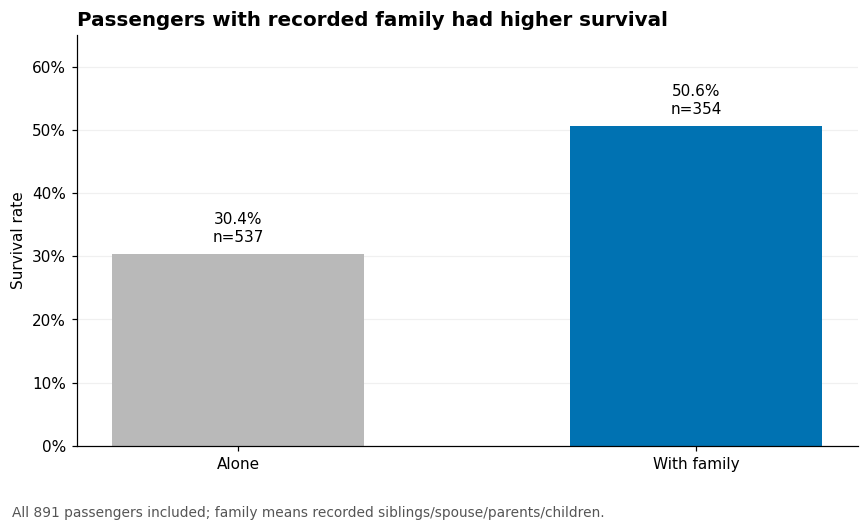

In [2]:
family = df.groupby('TravelGroup').agg(passengers=('Survived', 'size'),
    survivors=('Survived', 'sum'), survival_rate=('Survived', 'mean')).reindex(['Alone', 'With family'])
family['survival_pct'] = family.survival_rate * 100
family.to_csv(RESULTS / 'family_survival.csv')
display(family.round(3))
alone, accompanied = family.loc['Alone', 'survival_pct'], family.loc['With family', 'survival_pct']
display(Markdown(f'**Answer:** Alone: **{alone:.1f}%** survived; with family: **{accompanied:.1f}%** survived. '
    f'Travelling alone was associated with **{accompanied-alone:.1f} percentage points lower survival**. '
    'This is an association, not proof that being alone caused the difference.'))
fig, ax = plt.subplots()
bars = ax.bar(family.index, family.survival_pct, color=[GREY, BLUE], width=.55)
for b, (group, row) in zip(bars, family.iterrows()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+2,
            f'{row.survival_pct:.1f}%\nn={int(row.passengers)}', ha='center')
ax.set(title='Passengers with recorded family had higher survival', ylabel='Survival rate', ylim=(0, 65))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.xaxis.grid(False)
finish(fig, '01_alone_vs_family.png', 'All 891 passengers included; family means recorded siblings/spouse/parents/children.')

,passengers,survivors,survival_rate,survival_pct
FamilySize,,,,
1,537,163,0.304,30.354
2,161,89,0.553,55.280
3,102,59,0.578,57.843
4,29,21,0.724,72.414
5,15,3,0.200,20.000
6,22,3,0.136,13.636
7,12,4,0.333,33.333
8,6,0,0.000,0.000
11,7,0,0.000,0.000


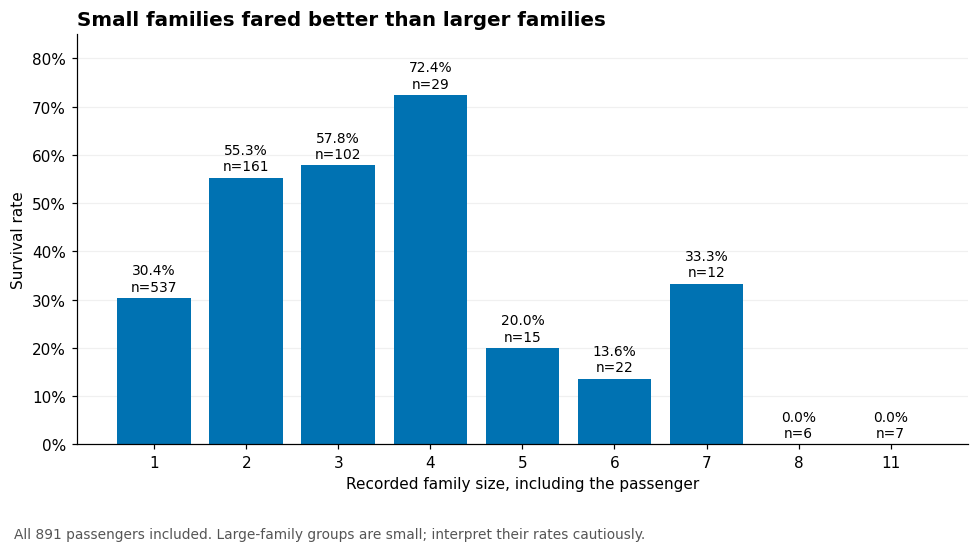

In [3]:
by_size = df.groupby('FamilySize').agg(passengers=('Survived','size'),
    survivors=('Survived','sum'), survival_rate=('Survived','mean'))
by_size['survival_pct'] = by_size.survival_rate * 100
display(by_size.round(3))
by_size.to_csv(RESULTS / 'family_size_survival.csv')
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(by_size.index.astype(str), by_size.survival_pct, color=BLUE)
for b, row in zip(bars, by_size.itertuples()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.5,
            f'{row.survival_pct:.1f}%\nn={row.passengers}', ha='center', fontsize=9)
ax.set(title='Small families fared better than larger families',
       xlabel='Recorded family size, including the passenger', ylabel='Survival rate', ylim=(0, 85))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.xaxis.grid(False)
finish(fig, '02_exact_family_size.png', 'All 891 passengers included. Large-family groups are small; interpret their rates cautiously.')

**Interpretation:** Combining all family sizes masks variation: families of two to four had relatively high survival, while some larger-family groups had low survival. Sex, class, age, and other circumstances may explain part of the association. Family size 11 contains only seven passengers; its 0% rate is not a reliable prediction for future groups.

## Exercise 2 — Embarkation port and passenger class
**Question:** Is there a survival difference by port, and is port standing in for class?

**Chart choices:** A sorted bar chart compares crude port survival rates. A 100% stacked bar reveals each port's class composition. Three small multiples compare ports **within the same class** using a shared 0–100% scale. Direct standardization then applies the same class weights to each port, allowing a more comparable descriptive summary.

,passengers,survivors,survival_rate,survival_pct
Port,,,,
Cherbourg,168,93,0.554,55.357
Queenstown,77,30,0.390,38.961
Southampton,644,217,0.337,33.696


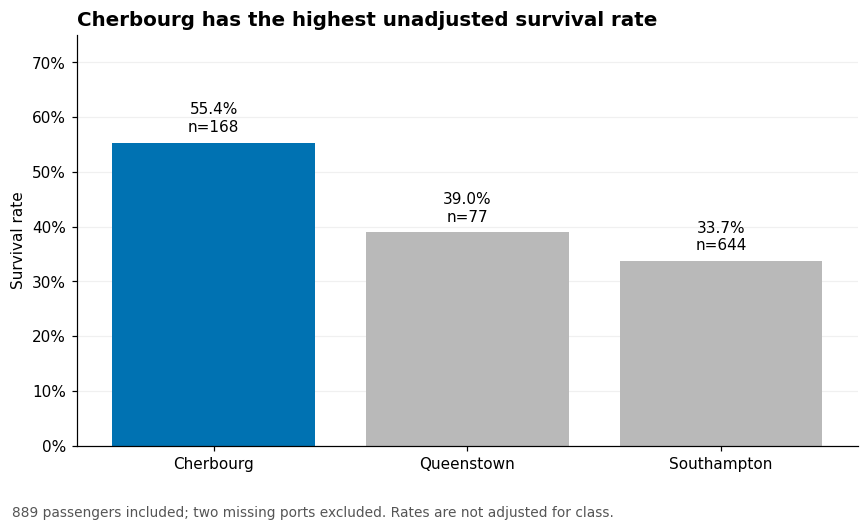

In [4]:
port_df = df.dropna(subset=['Port']).copy()
assert len(port_df) == 889
by_port = port_df.groupby('Port').agg(passengers=('Survived','size'),
    survivors=('Survived','sum'), survival_rate=('Survived','mean'))
by_port['survival_pct'] = by_port.survival_rate * 100
by_port = by_port.sort_values('survival_pct', ascending=False)
display(by_port.round(3)); by_port.to_csv(RESULTS / 'port_survival.csv')
fig, ax = plt.subplots()
bars = ax.bar(by_port.index, by_port.survival_pct, color=[BLUE, GREY, GREY])
for b, row in zip(bars, by_port.itertuples()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+2,
            f'{row.survival_pct:.1f}%\nn={row.passengers}', ha='center')
ax.set(title='Cherbourg has the highest unadjusted survival rate', ylabel='Survival rate', ylim=(0, 75))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.xaxis.grid(False)
finish(fig, '03_crude_port_rates.png', '889 passengers included; two missing ports excluded. Rates are not adjusted for class.')

Pclass,1,2,3
Port,,,
Cherbourg,85,17,66
Queenstown,2,3,72
Southampton,127,164,353


Pclass,1,2,3
Port,,,
Cherbourg,50.6,10.1,39.3
Queenstown,2.6,3.9,93.5
Southampton,19.7,25.5,54.8


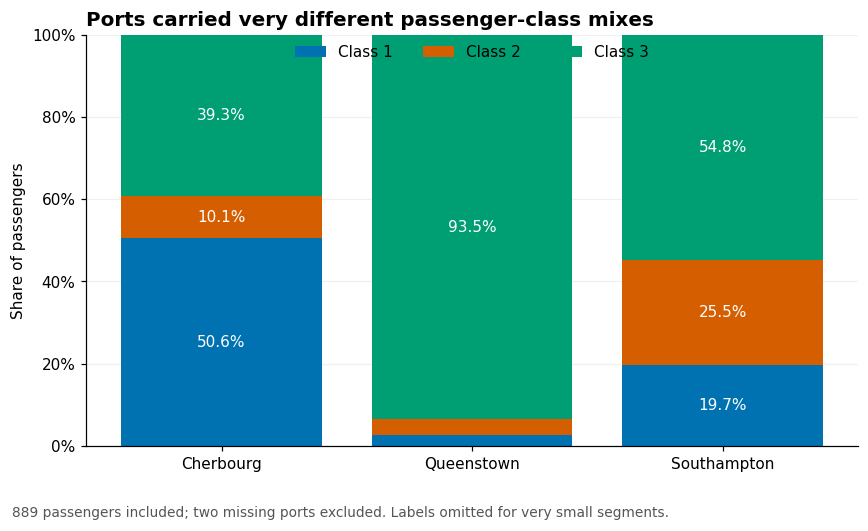

In [5]:
port_order = ['Cherbourg', 'Queenstown', 'Southampton']
composition = pd.crosstab(port_df.Port, port_df.Pclass).reindex(port_order)
composition_pct = composition.div(composition.sum(axis=1), axis=0) * 100
display(composition); display(composition_pct.round(1))
composition_pct.to_csv(RESULTS / 'port_class_composition_pct.csv')
fig, ax = plt.subplots()
bottom = np.zeros(3)
for cls, color in zip([1,2,3], [BLUE, ORANGE, GREEN]):
    values = composition_pct[cls].to_numpy()
    ax.bar(port_order, values, bottom=bottom, color=color, label=f'Class {cls}')
    for i, val in enumerate(values):
        if val >= 8: ax.text(i, bottom[i]+val/2, f'{val:.1f}%', ha='center', va='center', color='white')
    bottom += values
ax.set(title='Ports carried very different passenger-class mixes', ylabel='Share of passengers', ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.xaxis.grid(False)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, 1.01), frameon=False)
finish(fig, '04_class_mix_by_port.png', '889 passengers included; two missing ports excluded. Labels omitted for very small segments.')

passengers  survivors  survival_rate  survival_pct
Port        Pclass                                                    
Cherbourg   1               85         59          0.694        69.412
            2               17          9          0.529        52.941
            3               66         25          0.379        37.879
Queenstown  1                2          1          0.500        50.000
            2                3          2          0.667        66.667
            3               72         27          0.375        37.500
Southampton 1              127         74          0.583        58.268
            2              164         76          0.463        46.341
            3              353         67          0.190        18.980

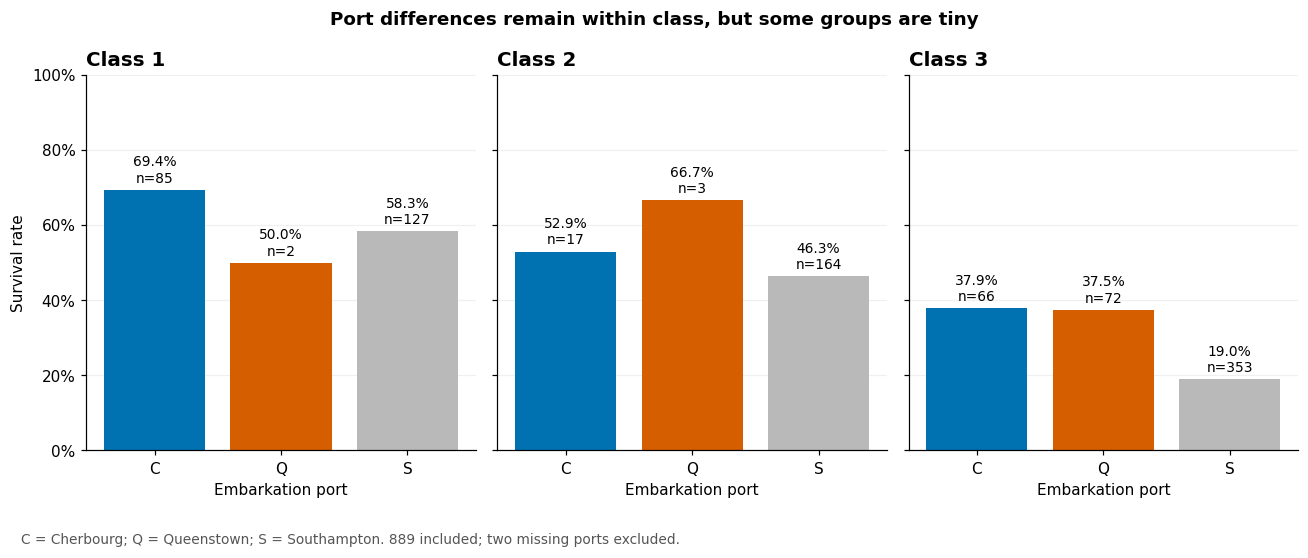

In [6]:
by_port_class = port_df.groupby(['Port', 'Pclass']).agg(passengers=('Survived','size'),
    survivors=('Survived','sum'), survival_rate=('Survived','mean'))
by_port_class['survival_pct'] = by_port_class.survival_rate * 100
display(by_port_class.round(3)); by_port_class.to_csv(RESULTS / 'port_class_survival.csv')
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)
for cls, ax in zip([1,2,3], axes):
    group = by_port_class.xs(cls, level='Pclass').reindex(port_order)
    bars = ax.bar(['C', 'Q', 'S'], group.survival_pct, color=[BLUE, ORANGE, GREY])
    for b, row in zip(bars, group.itertuples()):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+2,
                f'{row.survival_pct:.1f}%\nn={row.passengers}', ha='center', fontsize=9)
    ax.set(title=f'Class {cls}', ylim=(0, 100), xlabel='Embarkation port')
    ax.xaxis.grid(False); ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set_ylabel('Survival rate')
fig.suptitle('Port differences remain within class, but some groups are tiny', fontweight='bold')
finish(fig, '05_ports_within_class.png', 'C = Cherbourg; Q = Queenstown; S = Southampton. 889 included; two missing ports excluded.')

,Common class weight
Pclass,
1,0.240720
2,0.206974
3,0.552306


,Crude survival (%),Class-standardized survival (%)
Port,,
Cherbourg,55.36,48.59
Queenstown,38.96,46.55
Southampton,33.70,34.10


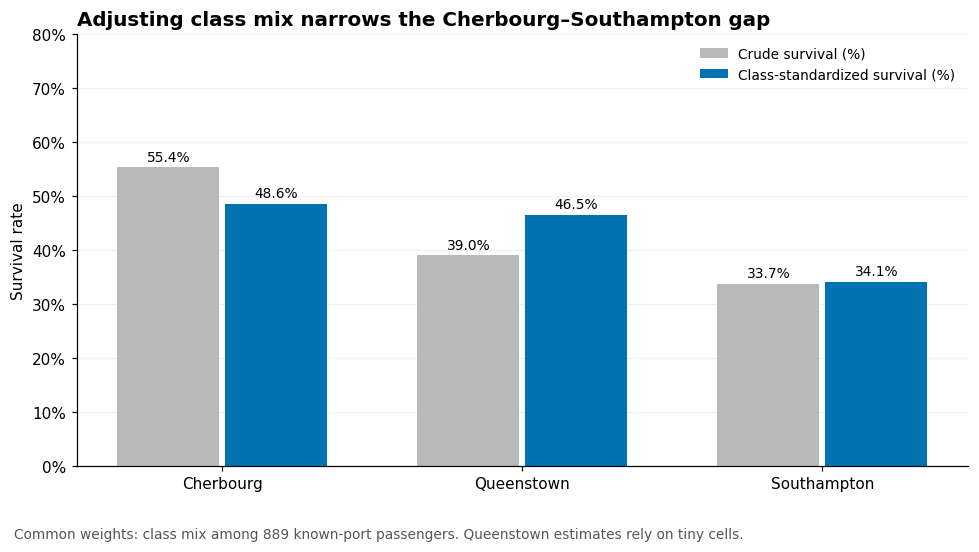

**Answer:** The Cherbourg–Southampton gap falls from **21.7** to **14.5 percentage points** after class standardization. Class composition explains part of the crude difference, but the difference does not disappear. Queenstown has only two first-class and three second-class passengers, so its standardized rate is unstable. Other factors, especially sex and age, can still confound these descriptive comparisons. A residual association does not prove that the port itself caused better survival.

In [7]:
# Use the class distribution of all passengers with known ports as common weights.
weights = port_df.Pclass.value_counts(normalize=True).sort_index()
rate_matrix = by_port_class.survival_rate.unstack('Pclass').reindex(port_order)
adjusted = rate_matrix.mul(weights, axis=1).sum(axis=1) * 100
comparison = pd.DataFrame({'Crude survival (%)': by_port.survival_pct,
    'Class-standardized survival (%)': adjusted}).reindex(port_order)
display(weights.rename('Common class weight').to_frame())
display(comparison.round(2)); comparison.to_csv(RESULTS / 'port_class_standardized.csv')
fig, ax = plt.subplots(figsize=(9,5))
positions = np.arange(3)
for offset, column, color in [(-.18, comparison.columns[0], GREY), (.18, comparison.columns[1], BLUE)]:
    bars = ax.bar(positions+offset, comparison[column], width=.34, color=color, label=column)
    for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.2,
        f'{b.get_height():.1f}%', ha='center', fontsize=9)
ax.set_xticks(positions, port_order)
ax.set(title='Adjusting class mix narrows the Cherbourg–Southampton gap', ylabel='Survival rate', ylim=(0,80))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.xaxis.grid(False)
ax.legend(frameon=False, fontsize=9)
finish(fig, '06_crude_vs_standardized.png', 'Common weights: class mix among 889 known-port passengers. Queenstown estimates rely on tiny cells.')
crude_gap = comparison.loc['Cherbourg'].iloc[0] - comparison.loc['Southampton'].iloc[0]
adjusted_gap = comparison.loc['Cherbourg'].iloc[1] - comparison.loc['Southampton'].iloc[1]
display(Markdown(f'**Answer:** The Cherbourg–Southampton gap falls from **{crude_gap:.1f}** to '
    f'**{adjusted_gap:.1f} percentage points** after class standardization. '
    'Class composition explains part of the crude difference, but the difference does not disappear. '
    'Queenstown has only two first-class and three second-class passengers, so its standardized rate is unstable. '
    'Other factors, especially sex and age, can still confound these descriptive comparisons. '
    'A residual association does not prove that the port itself caused better survival.'))

## Exercise 3 — Find and fix a published bad chart
**Selected example:** A Fox News graphic comparing Affordable Care Act sign-ups and a target, reproduced and discussed in [The Week](https://theweek.com/speedreads/455727/fox-news-chart-conveniently-distorts-obamacare-enrollments). [TPM](https://talkingpointsmemo.com/livewire/fox-corrects-misleading-graphic) documents the subsequent correction. This is a historical chart-design example, not a claim about current enrolment.

**Two broken rules:**
1. The bars do not use a zero baseline, exaggerating the difference in their lengths.
2. The vertical axis has no readable scale, concealing the truncation and preventing readers from checking the encoded lengths.

**Redesign:** Use flat bars from zero, label the scale in millions, label each value, and use restrained color. The sketch below uses the rounded 6 million versus 7 million figures discussed in the coverage; it is not a precision reconstruction of the original target marked “7 million plus.”

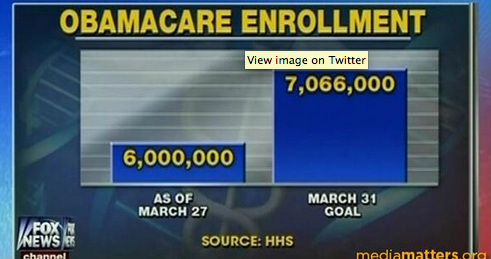

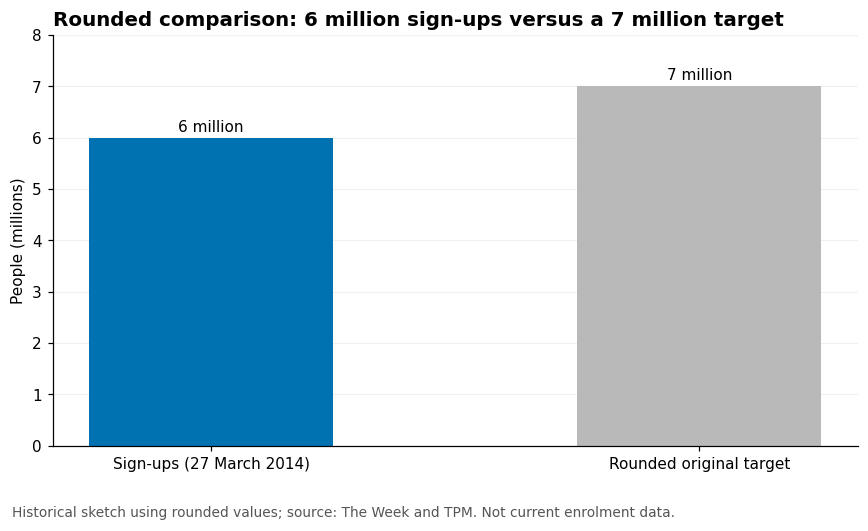

In [8]:
reference = Path('references/original_bad_chart.png')
if reference.exists():
    display(Image(filename=str(reference)))
else:
    display(Markdown('Original graphic: [view it on The Week](https://theweek.com/speedreads/455727/fox-news-chart-conveniently-distorts-obamacare-enrollments).'))

news_values = [6.0, 7.0]  # Rounded illustration of the comparison discussed by the sources.
fig, ax = plt.subplots()
bars = ax.bar(['Sign-ups (27 March 2014)', 'Rounded original target'], news_values,
              color=[BLUE, GREY], width=.5)
for b, value in zip(bars, news_values):
    ax.text(b.get_x()+b.get_width()/2, value+.12, f'{value:.0f} million', ha='center')
ax.set(title='Rounded comparison: 6 million sign-ups versus a 7 million target',
       ylabel='People (millions)', ylim=(0, 8))
ax.xaxis.grid(False)
finish(fig, '07_published_chart_redesign.png', 'Historical sketch using rounded values; source: The Week and TPM. Not current enrolment data.')

**What changes:** The redesigned chart shows a modest gap rather than suggesting sign-ups were a tiny fraction of the target. It also separates chart geometry from the policy debate: the older target was revised, as noted by TPM. A precise factual chart should state which target and date it uses. The purpose here is to correct the visual encoding, not decide that debate.

## Exercise 4 — Deliberately redraw a lecture chart badly
**Selected lecture chart:** Survival rate by passenger class.

The next figure is explicitly an anti-example. It intentionally truncates the bar axis, uses decorative rainbow colors for a single series, and overlays average fare on a second vertical axis. The adjacent correct version uses the same rates, a zero baseline, and one measure.

True first/third-class rate ratio: 2.60x
Visible bar-height ratio with a 20% baseline: 10.14x


,passengers,survival_rate,mean_fare,survival_pct
Pclass,,,,
1,216,0.630,84.155,62.963
2,184,0.473,20.662,47.283
3,491,0.242,13.676,24.236


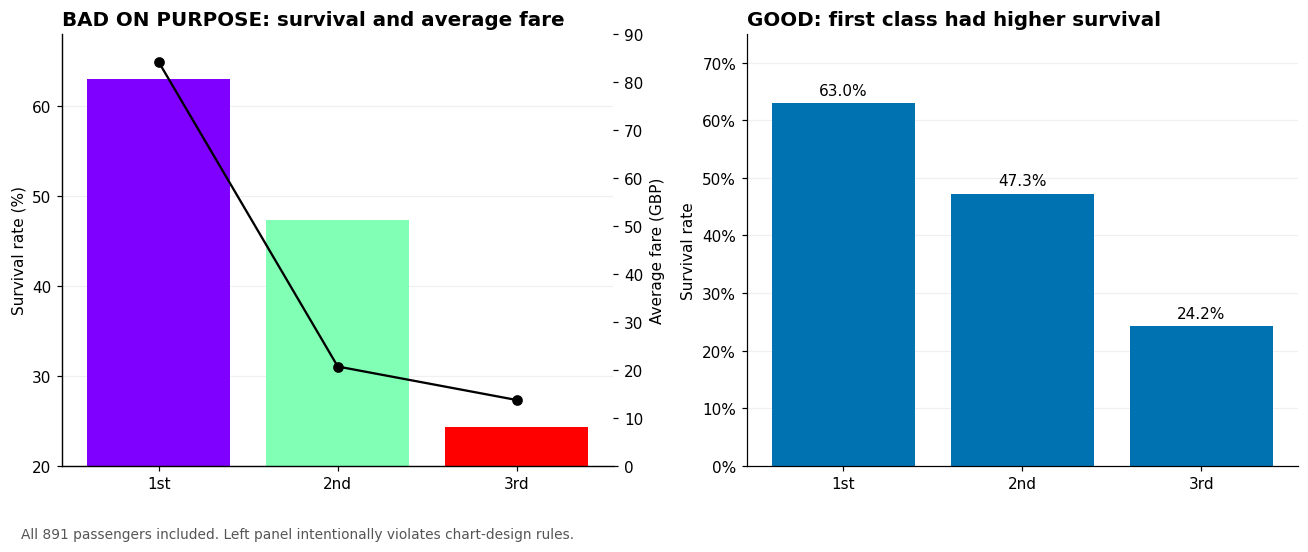

In [9]:
class_summary = df.groupby('Pclass').agg(passengers=('Survived','size'),
    survival_rate=('Survived','mean'), mean_fare=('Fare','mean'))
class_summary['survival_pct'] = class_summary.survival_rate * 100
display(class_summary.round(3)); class_summary.to_csv(RESULTS / 'class_survival_fare.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(3)
bad, good = axes
bad.bar(x, class_summary.survival_pct, color=plt.cm.rainbow(np.linspace(0,1,3)))
bad.set_xticks(x, ['1st', '2nd', '3rd'])
bad.set(title='BAD ON PURPOSE: survival and average fare', ylabel='Survival rate (%)', ylim=(20, 68))
bad.xaxis.grid(False)
other = bad.twinx()
other.plot(x, class_summary.mean_fare, color='black', marker='o')
other.set_ylabel('Average fare (GBP)'); other.set_ylim(0, 90); other.grid(False)
bars = good.bar(x, class_summary.survival_pct, color=BLUE)
good.set_xticks(x, ['1st', '2nd', '3rd'])
for b, val in zip(bars, class_summary.survival_pct):
    good.text(b.get_x()+b.get_width()/2, val+1.5, f'{val:.1f}%', ha='center')
good.set(title='GOOD: first class had higher survival', ylabel='Survival rate', ylim=(0, 75))
good.yaxis.set_major_formatter(PercentFormatter(100)); good.xaxis.grid(False)
finish(fig, '08_bad_vs_good_lecture_chart.png', 'All 891 passengers included. Left panel intentionally violates chart-design rules.')
true_ratio = class_summary.loc[1,'survival_pct'] / class_summary.loc[3,'survival_pct']
visible_ratio = (class_summary.loc[1,'survival_pct']-20) / (class_summary.loc[3,'survival_pct']-20)
print(f'True first/third-class rate ratio: {true_ratio:.2f}x')
print(f'Visible bar-height ratio with a 20% baseline: {visible_ratio:.2f}x')

**What a reader would wrongly conclude:** The truncated bar axis makes the first-class advantage look much larger than it is: the visible bars suggest roughly a tenfold gap, while the actual survival-rate ratio is about 2.6. The rainbow implies that color carries extra meaning even though there is only one survival series. The fare line on a second scale can suggest that fare tracks survival precisely or caused it; its apparent alignment depends on the arbitrary right-axis limits. The data shows an association between class and survival, but neither arbitrary geometry nor a dual-axis overlay proves causation.

## Completion and reproducibility
All four supplied notebook exercises have code, numerical output, charts, and written answers. No passengers are removed for missing age. Port analyses explicitly exclude the two unknown ports. Small groups are labelled with their sample sizes.

The ZIP includes the original uploads, the lecture notebook, this solution notebook, a Python-script version, both lecture datasets, exported charts and tables, dependencies, and run instructions. The five separate README assignments remain outside the completed scope because their exact briefs were not attached.